In [4]:
import json
from copy import deepcopy
from pathlib import Path

import plotnine as gg
import polars as pl

pl.Config.set_fmt_str_lengths(900)
pl.Config.set_tbl_width_chars(900)


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
PROJECT_DIR = Path().resolve() / ".."
OUTPUT_DIR = PROJECT_DIR / "output"

SELECTED_TEST_RUN_TYPE = "file-stack"
SELECTED_TEST_RUN_IDS = [
    # Full 1
    "full_2026-08-02_14-48-28_n-62-11-61_none",
    "full_2026-08-02_14-48-29_n-62-11-60_none",
]
DATASET_NAME = "Canislupus_CZM_712"

datas = []
for i, run_id in enumerate(SELECTED_TEST_RUN_IDS):
    RUN_DIR = OUTPUT_DIR / SELECTED_TEST_RUN_TYPE / run_id / DATASET_NAME
    assert RUN_DIR.exists(), f"Run directory {RUN_DIR} does not exist"

    # Load data
    for file in RUN_DIR.glob("*.json"):
        with file.open("r") as f:
            test_data = json.load(f)

        test_data["run_id"] = f"{i}::{test_data['name']}"
        datas.append(test_data)
        print(f"Loaded test data from {file.name}:")

Loaded test data from test_tifffile_lerc_effort_z0_s0_p22.json:
Loaded test data from test_tifffile_deflate_pred2_p12.json:
Loaded test data from test_libtiff_lzma_pred2_p4.json:
Loaded test data from test_tifffile_lerc_effort_z0_s0_p20.json:
Loaded test data from test_libtiff_deflate_pred2_s1_p1.json:
Loaded test data from test_imagemagick_deflate_pred1_p2.json:
Loaded test data from test_imagemagick_lerc_effort_z0_s0_p18.json:
Loaded test data from test_tifffile_lzma_pred2_p5.json:
Loaded test data from test_tifffile_lerc_effort_z0_s0_p8.json:
Loaded test data from test_tifffile_deflate_pred2_p1.json:
Loaded test data from test_libtiff_deflate_pred1_s1_p2.json:
Loaded test data from test_tifffile_zstd_pred2_p19.json:
Loaded test data from test_imagemagick_lzma_pred2_p5.json:
Loaded test data from test_libtiff_deflate_pred2_s0_p5.json:
Loaded test data from test_tifffile_lzma_pred1_p9.json:
Loaded test data from test_tifffile_lerc_effort_z0_s2_p1.json:
Loaded test data from test_libti

In [8]:
from collections.abc import Mapping, Sequence


def flatten(data, prefix: str = "", sep: str = "__") -> dict:
    flattened = {}

    if isinstance(data, Mapping):
        for key, value in data.items():
            column = f"{prefix}{sep}{key}" if prefix else str(key)
            flattened.update(flatten(value, column, sep))

    elif isinstance(data, Sequence) and not isinstance(data, (str, bytes)):
        for index, value in enumerate(data):
            column = f"{prefix}[{index}]"
            flattened.update(flatten(value, column, sep))

    else:
        flattened[prefix] = data

    return flattened


rows = []
for data in datas:
    row = deepcopy(data)

    # Clean up a bit to reduce noise
    # TODO THIS IS REFACTORED
    # row.pop("array_info")
    # row["baseline_test"].pop("array_info")

    rows.append({**row, **flatten(row)})

df = pl.DataFrame(rows, strict=False)
df


name,series,subseries,paradigm,lossless,allowed_dtypes,implementation,differencing,predictor,effort,quality,tolerance,subcodec,subcodec_index,extra,id,dataset_name,dataset_path,start_wall_dt,end_wall_dt,total_wall_time_seconds,config,baseline_test,host,compress_wall_time_seconds,compress_user_time_seconds,compress_system_time_seconds,decompress_wall_time_seconds,decompress_user_time_seconds,decompress_system_time_seconds,uncompressed_size,actual_uncompressed_size,compressed_size,n_elements,compression_wall_rate,compression_user_rate,decompression_wall_rate,…,images_compressed_sizes__Canislupus_CZM_712_0896.tif,images_compressed_sizes__Canislupus_CZM_712_0646.tif,images_compressed_sizes__Canislupus_CZM_712_1012.tif,images_compressed_sizes__Canislupus_CZM_712_1389.tif,images_compressed_sizes__Canislupus_CZM_712_1444.tif,images_compressed_sizes__Canislupus_CZM_712_0422.tif,images_compressed_sizes__Canislupus_CZM_712_0114.tif,images_compressed_sizes__Canislupus_CZM_712_0221.tif,images_compressed_sizes__Canislupus_CZM_712_0432.tif,images_compressed_sizes__Canislupus_CZM_712_1430.tif,images_compressed_sizes__Canislupus_CZM_712_1217.tif,images_compressed_sizes__Canislupus_CZM_712_0410.tif,images_compressed_sizes__Canislupus_CZM_712_1266.tif,images_compressed_sizes__Canislupus_CZM_712_0612.tif,images_compressed_sizes__Canislupus_CZM_712_1064.tif,images_compressed_sizes__Canislupus_CZM_712_0332.tif,images_compressed_sizes__Canislupus_CZM_712_0526.tif,images_compressed_sizes__Canislupus_CZM_712_0706.tif,images_compressed_sizes__Canislupus_CZM_712_1132.tif,images_compressed_sizes__Canislupus_CZM_712_0621.tif,images_compressed_sizes__Canislupus_CZM_712_0902.tif,runner_extra__bulk_runner_kwargs__n_jobs,runner_extra__bulk_runner_kwargs__joblib_kwargs__prefer,config__compressor[2]__predictor,config__compressor[1][1],config__comparer[1][0],config__compressor[1][2],config__compressor[1][3],config__compressor[1][4],config__compressor[1][5],config__compressor[2]__compressionargs__compression,config__compressor[2]__compressionargs__compressionargs__level,config__compressor[2]__compressionargs__lossless,config__compressor[2]__compressionargs__predictor,config__compressor[1][6],config__compressor[1][7],config__compressor[2]__compressionargs__reversible
str,str,str,str,bool,list[str],str,str,i64,i64,i64,null,str,i64,struct[0],str,str,str,str,str,f64,struct[18],null,str,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,f64,f64,f64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,i64,str,str,str,str,str,str,str,i64,bool,i64,str,str,bool
"""tifffile_lerc_effort_z0_s0_p22""","""tiff-lerc""",null,"""file_stack""",true,"[""<u2"", ""<f4"", … ""<f2""]","""tifffile""",null,null,22,null,null,"""none""",0,{},"""{""name"":""tifffile_lerc_effort_z0_s0_p22"",""series"":""tiff-lerc"",""subseries"":null,""paradigm"":""file_stack"",""lossless"":true,""allowed_dtypes"":[""<u2"",""<f4"",""<f8"",""<i2"",""<c8"",""<u4"",""<c32"",""|b1"",""<f16"",""<i4"",""<i8"",""|i1"",""<c16"",""|u1"",""<u8"",""<f2""],""implementation"":""tifffile"",""differencing"":null,""predictor"":null,""effort"":22,""quality"":null,""tolerance"":null,""subcodec"":""none"",""subcodec_index"":0,""extra"":{},""compressor"":[""tifffile.compress"",[""lerc""],{""compressionargs"":{""level"":0}}],""decompressor"":[""tifffile.decompress"",[],{}],""comparer"":[""tifffile.compare"",[],{}]}""","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-08-02T13:34:34.809506Z""","""2026-08-02T13:34:50.794532Z""",15.985028,"{""tifffile_lerc_effort_z0_s0_p22"",""tiff-lerc"",null,""file_stack"",true,[""<u2"", ""<f4"", … ""<f2""],""tifffile"",null,null,22,null,null,""none"",0,{},[""tifffile.compress"", ""[lerc]"", ""{{0}}""],[""tifffile.decompress"", ""[]"", ""{}""],[""tifffile.compare"", ""[]"", ""{}""]}",null,"""n-62-11-61""",7.984513,129.977671,9.012809,3.333263,40.007581,12.577746,12576198072,1257640

In [9]:
df

name,series,subseries,paradigm,lossless,allowed_dtypes,implementation,differencing,predictor,effort,quality,tolerance,subcodec,subcodec_index,extra,id,dataset_name,dataset_path,start_wall_dt,end_wall_dt,total_wall_time_seconds,config,baseline_test,host,compress_wall_time_seconds,compress_user_time_seconds,compress_system_time_seconds,decompress_wall_time_seconds,decompress_user_time_seconds,decompress_system_time_seconds,uncompressed_size,actual_uncompressed_size,compressed_size,n_elements,compression_wall_rate,compression_user_rate,decompression_wall_rate,…,images_compressed_sizes__Canislupus_CZM_712_0896.tif,images_compressed_sizes__Canislupus_CZM_712_0646.tif,images_compressed_sizes__Canislupus_CZM_712_1012.tif,images_compressed_sizes__Canislupus_CZM_712_1389.tif,images_compressed_sizes__Canislupus_CZM_712_1444.tif,images_compressed_sizes__Canislupus_CZM_712_0422.tif,images_compressed_sizes__Canislupus_CZM_712_0114.tif,images_compressed_sizes__Canislupus_CZM_712_0221.tif,images_compressed_sizes__Canislupus_CZM_712_0432.tif,images_compressed_sizes__Canislupus_CZM_712_1430.tif,images_compressed_sizes__Canislupus_CZM_712_1217.tif,images_compressed_sizes__Canislupus_CZM_712_0410.tif,images_compressed_sizes__Canislupus_CZM_712_1266.tif,images_compressed_sizes__Canislupus_CZM_712_0612.tif,images_compressed_sizes__Canislupus_CZM_712_1064.tif,images_compressed_sizes__Canislupus_CZM_712_0332.tif,images_compressed_sizes__Canislupus_CZM_712_0526.tif,images_compressed_sizes__Canislupus_CZM_712_0706.tif,images_compressed_sizes__Canislupus_CZM_712_1132.tif,images_compressed_sizes__Canislupus_CZM_712_0621.tif,images_compressed_sizes__Canislupus_CZM_712_0902.tif,runner_extra__bulk_runner_kwargs__n_jobs,runner_extra__bulk_runner_kwargs__joblib_kwargs__prefer,config__compressor[2]__predictor,config__compressor[1][1],config__comparer[1][0],config__compressor[1][2],config__compressor[1][3],config__compressor[1][4],config__compressor[1][5],config__compressor[2]__compressionargs__compression,config__compressor[2]__compressionargs__compressionargs__level,config__compressor[2]__compressionargs__lossless,config__compressor[2]__compressionargs__predictor,config__compressor[1][6],config__compressor[1][7],config__compressor[2]__compressionargs__reversible
str,str,str,str,bool,list[str],str,str,i64,i64,i64,null,str,i64,struct[0],str,str,str,str,str,f64,struct[18],null,str,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,f64,f64,f64,…,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,str,i64,str,str,str,str,str,str,str,i64,bool,i64,str,str,bool
"""tifffile_lerc_effort_z0_s0_p22""","""tiff-lerc""",null,"""file_stack""",true,"[""<u2"", ""<f4"", … ""<f2""]","""tifffile""",null,null,22,null,null,"""none""",0,{},"""{""name"":""tifffile_lerc_effort_z0_s0_p22"",""series"":""tiff-lerc"",""subseries"":null,""paradigm"":""file_stack"",""lossless"":true,""allowed_dtypes"":[""<u2"",""<f4"",""<f8"",""<i2"",""<c8"",""<u4"",""<c32"",""|b1"",""<f16"",""<i4"",""<i8"",""|i1"",""<c16"",""|u1"",""<u8"",""<f2""],""implementation"":""tifffile"",""differencing"":null,""predictor"":null,""effort"":22,""quality"":null,""tolerance"":null,""subcodec"":""none"",""subcodec_index"":0,""extra"":{},""compressor"":[""tifffile.compress"",[""lerc""],{""compressionargs"":{""level"":0}}],""decompressor"":[""tifffile.decompress"",[],{}],""comparer"":[""tifffile.compare"",[],{}]}""","""Canislupus_CZM_712""","""/dtu/3d-imaging-center/projects/2026_DANFIX_201/analysis/compression/datasets/Canislupus_CZM_712""","""2026-08-02T13:34:34.809506Z""","""2026-08-02T13:34:50.794532Z""",15.985028,"{""tifffile_lerc_effort_z0_s0_p22"",""tiff-lerc"",null,""file_stack"",true,[""<u2"", ""<f4"", … ""<f2""],""tifffile"",null,null,22,null,null,""none"",0,{},[""tifffile.compress"", ""[lerc]"", ""{{0}}""],[""tifffile.decompress"", ""[]"", ""{}""],[""tifffile.compare"", ""[]"", ""{}""]}",null,"""n-62-11-61""",7.984513,129.977671,9.012809,3.333263,40.007581,12.577746,12576198072,1257640

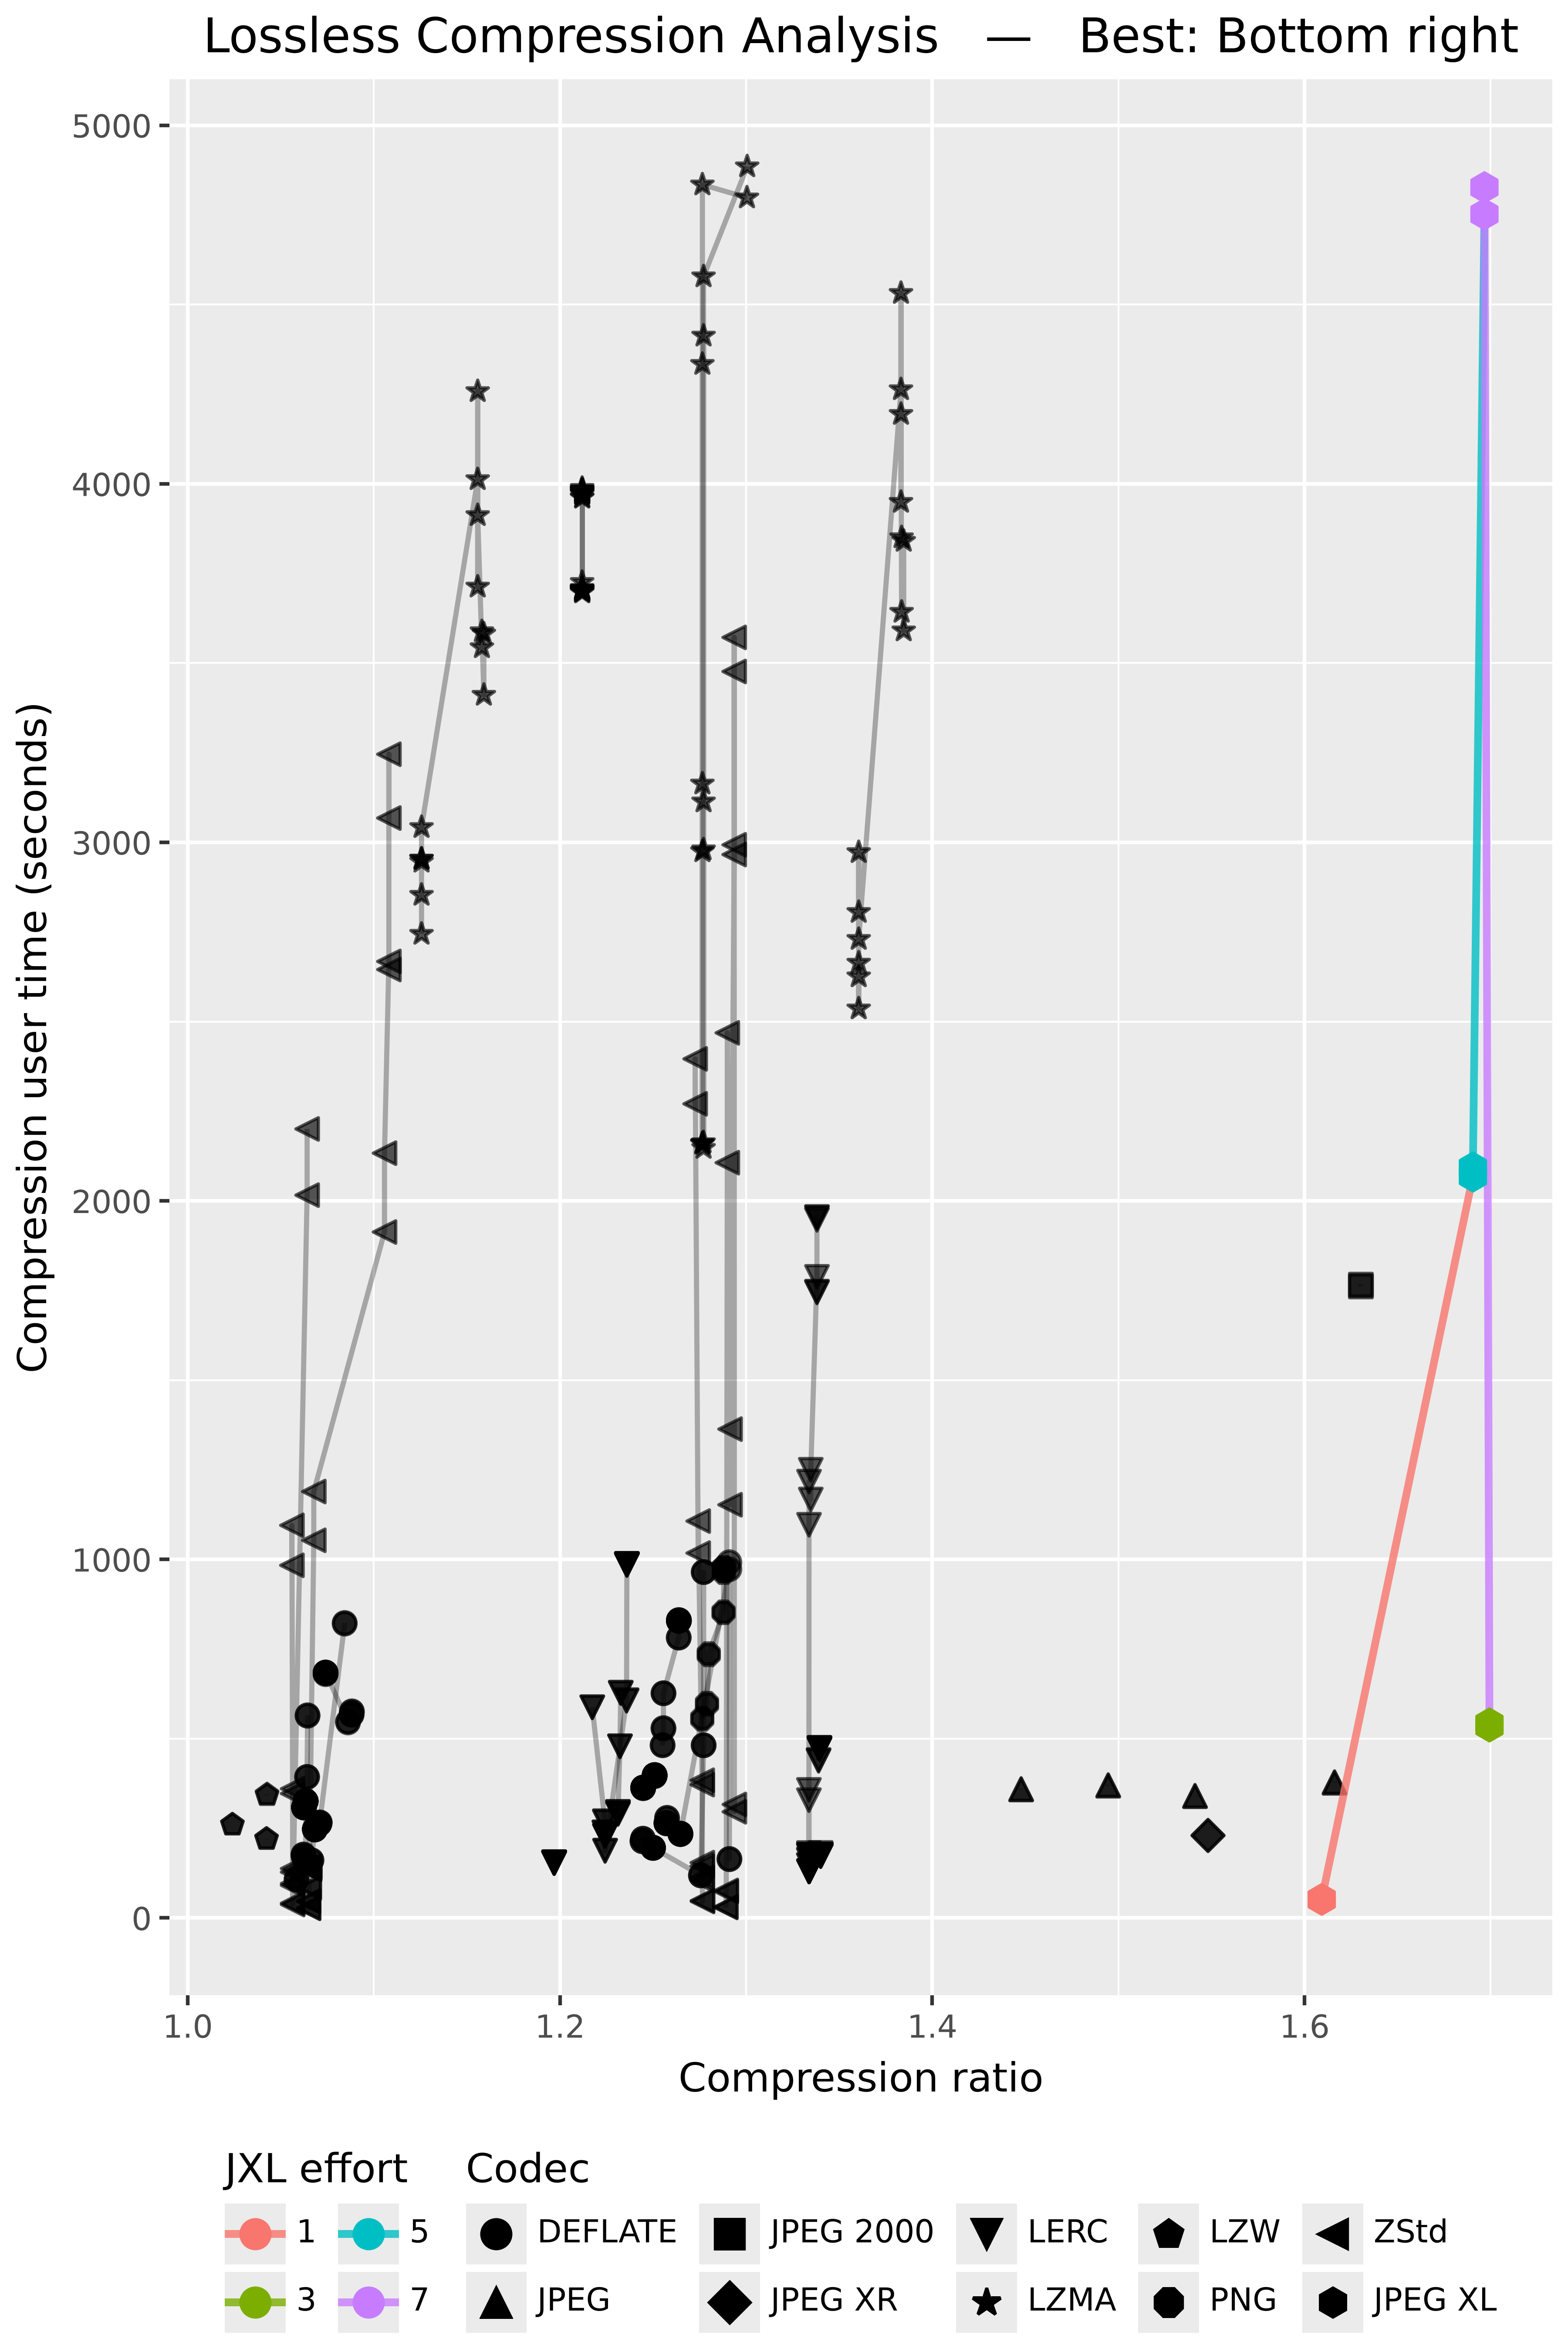

In [10]:
time_col = "compress_user_time_seconds"
ratio_col = "compression_ratio"

selected_cols = [
    "series",
    "implementation",
    "subcodec",
    "subcodec_index",
    "differencing",
    "predictor",
    "effort",
    time_col,
    ratio_col,
]

df_selected = (
    df.filter(
        pl.col("lossless") == True,
        ~pl.col("series").is_in(["tiff-baseline", "tiff-rle"]),
    )
    .select(selected_cols)
    .filter(
        pl.col(time_col).is_not_null(),
        pl.col(time_col) <= 5_000,
        pl.col(ratio_col).is_not_null(),
        pl.col(ratio_col) >= 1,
    )
)

SERIES_LABELS = {
    "tiff-deflate": "DEFLATE",
    "tiff-jpeg": "JPEG",
    "tiff-jpeg2000": "JPEG 2000",
    "tiff-jpegxr": "JPEG XR",
    "tiff-jpegxl": "JPEG XL",
    "tiff-lerc": "LERC",
    "tiff-lzma": "LZMA",
    "tiff-lzw": "LZW",
    "tiff-png": "PNG",
    "tiff-rle": "RLE",
    "tiff-zstd": "ZStd",
}

# These fields separate trajectories without affecting their appearance.
groups = [
    "series",
    "implementation",
    "subcodec",
    "differencing",
    "predictor",
]

df_selected = df_selected.with_columns(
    pl.col("series").replace(SERIES_LABELS).alias("series_label"),
    pl.concat_str(
        [pl.col(column).cast(pl.String).fill_null("<null>") for column in groups],
        separator=":::",
    ).alias("group"),
)

is_jxl = pl.col("series").eq("tiff-jpegxl").fill_null(False)

df_jxl = df_selected.filter(is_jxl)
df_non_jxl = df_selected.filter(~is_jxl)

plot = (
    gg.ggplot(
        df_selected,
        gg.aes(
            x=ratio_col,
            y=time_col,
            shape="series_label",
            group="group",
        ),
    )
    # Non-JPEG-XL series are all black.
    + gg.geom_line(
        data=df_non_jxl,
        color="black",
        alpha=0.3,
        size=0.8,
    )
    + gg.geom_point(
        data=df_non_jxl,
        color="black",
        alpha=0.65,
        size=3,
    )
    # JPEG XL is colored by effort and drawn last.
    + gg.geom_line(
        data=df_jxl,
        mapping=gg.aes(color="factor(effort)"),
        alpha=0.8,
        size=1.2,
    )
    + gg.geom_point(
        data=df_jxl,
        mapping=gg.aes(color="factor(effort)"),
        size=4,
    )
    + gg.labs(
        title="Lossless Compression Analysis   —   Best: Bottom right",
        x="Compression ratio",
        y="Compression user time (seconds)",
    )
    + gg.scale_shape_discrete()
    + gg.scale_color_discrete()
    + gg.theme(
        figure_size=(6, 9),
        dpi=300,
        legend_position="bottom",
    )
    + gg.guides(
        color=gg.guide_legend(
            title="JXL effort",
            order=1,
            direction="vertical",
            nrow=2,
        ),
        shape=gg.guide_legend(
            title="Codec",
            order=2,
            direction="vertical",
            nrow=2,
        ),
    )
)

plot

In [ ]:
plot.draw().savefig(
    "2026-08-11_lossless_plot_tall.png", dpi=300, bbox_inches="tight", pad_inches=0.1
)

In [12]:
df.filter(pl.col("series") == "tiff-jpegxl")[selected_cols]

series,implementation,subcodec,subcodec_index,differencing,predictor,effort,compress_user_time_seconds,compression_ratio
str,str,str,i64,str,i64,i64,f64,f64
"""tiff-jpegxl""","""tifffile""",null,null,null,null,7,4752.092216,1.696675
"""tiff-jpegxl""","""tifffile""",null,null,null,null,5,2068.222084,1.690478
"""tiff-jpegxl""","""tifffile""",null,null,null,null,9,19504.234247,1.704302
"""tiff-jpegxl""","""tifffile""",null,null,null,null,3,534.17281,1.699374
"""tiff-jpegxl""","""tifffile""",null,null,null,null,1,50.792813,1.60926
"""tiff-jpegxl""","""tifffile""",null,null,null,null,7,4827.116861,1.696675
"""tiff-jpegxl""","""tifffile""",null,null,null,null,5,2092.811397,1.690478
"""tiff-jpegxl""","""tifffile""",null,null,null,null,9,19613.980171,1.704302
"""tiff-jpegxl""","""tifffile""",null,null,null,null,3,542.245113,1.699374
